# Task 2 (Task B): prueba local de gestos de una mano

La primera meta es **ver la webcam, dibujar los puntos de la mano y mostrar una orden estable**. Este notebook funciona en CPU y no envía órdenes al TurtleBot.

| Gesto | Orden propuesta |
| --- | --- |
| Índice extendido hacia arriba y otros tres dedos largos flexionados | `AVANZAR` |
| Índice hacia tu izquierda, frente a la webcam | `IZQUIERDA` |
| Índice hacia tu derecha, frente a la webcam | `DERECHA` |
| Palma abierta, sin mano, más de una mano o gesto ambiguo | `DETENER` |

El pulgar queda libre. Usa una mano aproximadamente de frente a la cámara y cambia su orientación para señalar. Son reglas iniciales: todavía hay que evaluarlas con manos reales. Los giros propuestos serán continuos, sujetos a las reglas que confirme el profesor.

La imagen se procesa y muestra **sin espejo**. Desde el ajuste del 5 de noviembre, frente a la webcam tu derecha ordena DERECHA del robot y tu izquierda, IZQUIERDA. El clasificador convierte el eje horizontal de la imagen una sola vez. Reinicia el kernel para cargar las reglas actualizadas.

**1. Comprobar el kernel.** Selecciona el Python de la `.venv` compartida en la raíz de Proyecto2. Este notebook está dentro de `task 2`; funciona con el directorio de trabajo en esa carpeta o en la raíz del proyecto. En VS Code: selector de kernel → entornos de Python → `.venv` de Proyecto2.

Las dependencias están en `task 2/requirements.txt`. Para instalarlas en otra computadora, desde la raíz de Proyecto2:

```bash
.venv/bin/python -m pip install -r "task 2/requirements.txt"
```

Después de la reorganización de carpetas, reinicia el kernel y ejecuta desde el principio. Si acabas de instalar paquetes con el notebook abierto, reinicia también el kernel.


In [1]:
pip install opencv2

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement opencv2 (from versions: none)
ERROR: No matching distribution found for opencv2


In [2]:
import sys
from pathlib import Path

DIRECTORIO_ACTUAL = Path.cwd().resolve()
CANDIDATAS = (DIRECTORIO_ACTUAL, DIRECTORIO_ACTUAL / 'task 2')
RAIZ = next((p for p in CANDIDATAS if (p / 'gestos.py').is_file()
             and (p / 'Tarea1.ipynb').is_file()), None)
if RAIZ is None:
    raise RuntimeError('Abre el notebook desde Proyecto2 o desde su carpeta task 2.')

RAIZ_PROYECTO = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print('Python:', sys.version.split()[0])
print('Ejecutable:', sys.executable)
print('Carpeta de Task 2:', RAIZ)
if Path(sys.prefix).resolve() != (RAIZ_PROYECTO / '.venv').resolve():
    raise RuntimeError('Selecciona el kernel de la .venv global de Proyecto2 y reinicia este notebook.')


Python: 3.13.1
Ejecutable: d:\proyecto_vision\turtlebot4-vision-proyecto\.venv\Scripts\python.exe
Carpeta de Task 2: D:\proyecto_vision\turtlebot4-vision-proyecto\task 2


In [3]:
import hashlib
import importlib.metadata as metadata
import shutil
import time
from urllib.request import urlopen

import cv2
import mediapipe as mp
import numpy as np
from IPython.display import Image, display
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from gestos import FiltroOrden, Gesto, Orden, interpretar_mano

for paquete in ('mediapipe', 'opencv-contrib-python', 'numpy', 'ipykernel'):
    print(f'{paquete}: {metadata.version(paquete)}')

mediapipe: 1.1.1
opencv-contrib-python: 4.14.0.94
numpy: 2.5.4
ipykernel: 7.4.0


**2. Preparar el modelo.** MediaPipe Hand Landmarker utiliza un modelo de detección y puntos de la mano. La celda descarga la versión 1 oficial solo si falta y verifica su SHA-256. Después puedes trabajar sin internet.

Fuente: [modelo y documentación oficial](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker). El archivo descargado está excluido de Git.

In [4]:
URL_MODELO = (
    'https://storage.googleapis.com/mediapipe-models/'
    'hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task'
)
SHA256_MODELO = 'fbc2a30080c3c557093b5ddfc334698132eb341044ccee322ccf8bcf3607cde1'
MODELO = RAIZ / 'modelos' / 'hand_landmarker.task'
MODELO.parent.mkdir(exist_ok=True)

if not MODELO.exists():
    temporal = MODELO.with_suffix('.task.part')
    try:
        with urlopen(URL_MODELO, timeout=30) as respuesta, temporal.open('wb') as salida:
            shutil.copyfileobj(respuesta, salida)
        if hashlib.sha256(temporal.read_bytes()).hexdigest() != SHA256_MODELO:
            raise RuntimeError('La descarga no coincide con el modelo esperado.')
        temporal.replace(MODELO)
    finally:
        temporal.unlink(missing_ok=True)

if hashlib.sha256(MODELO.read_bytes()).hexdigest() != SHA256_MODELO:
    raise RuntimeError('El modelo local no coincide. Revisa el archivo antes de reemplazarlo.')
print(f'Modelo verificado: {MODELO.name} ({MODELO.stat().st_size / 1e6:.2f} MB)')

Modelo verificado: hand_landmarker.task (7.82 MB)


**3. Comprobar inferencia sin cámara.** El modo `VIDEO` usa marcas de tiempo crecientes y aprovecha seguimiento entre fotogramas. Elegimos explícitamente CPU y permitimos detectar dos manos para rechazar escenas con más de una.

La imagen negra siguiente comprueba que el modelo carga y responde; no mide la precisión de los gestos.

In [5]:
def crear_detector():
    opciones = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=str(MODELO),
            delegate=python.BaseOptions.Delegate.CPU,
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.6,
        min_hand_presence_confidence=0.6,
        min_tracking_confidence=0.6,
    )
    return vision.HandLandmarker.create_from_options(opciones)

imagen_vacia = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=np.zeros((480, 640, 3), dtype=np.uint8),
)
inicio = time.perf_counter()
with crear_detector() as detector:
    resultado = detector.detect_for_video(imagen_vacia, 0)
print('Manos en imagen negra:', len(resultado.hand_landmarks))
print(f'Carga y primera inferencia: {1000 * (time.perf_counter() - inicio):.0f} ms')

Manos en imagen negra: 0
Carga y primera inferencia: 45215 ms


**4. Entender el filtro temporal.** Las reglas geométricas están en `gestos.py`: comprueban articulaciones de los dedos y la dirección del índice. El filtro exige 0.4 segundos de una orden sostenida. Al cambiar de dirección, primero detiene y pide confirmar la nueva. Detenerse no tiene espera.

Esta prueba usa órdenes inventadas para entender el filtro, sin webcam.

In [6]:
filtro_ejemplo = FiltroOrden(estabilidad_s=0.4, max_intervalo_s=0.5)
for instante, propuesta in [
    (0.00, Orden.AVANZAR),
    (0.20, Orden.AVANZAR),
    (0.41, Orden.AVANZAR),
    (0.50, Orden.DERECHA),
    (0.70, Orden.DERECHA),
    (0.91, Orden.DERECHA),
    (0.92, Orden.DETENER),
]:
    salida = filtro_ejemplo.actualizar(propuesta, instante)
    print(f'{instante:.2f}s | propuesta: {propuesta.value:9s} | salida: {salida.value}')

0.00s | propuesta: AVANZAR   | salida: DETENER
0.20s | propuesta: AVANZAR   | salida: DETENER
0.41s | propuesta: AVANZAR   | salida: AVANZAR
0.50s | propuesta: DERECHA   | salida: DETENER
0.70s | propuesta: DERECHA   | salida: DETENER
0.91s | propuesta: DERECHA   | salida: DERECHA
0.92s | propuesta: DETENER   | salida: DETENER


**5. Probar con webcam.** La última celda abre la cámara durante 60 segundos y muestra el resultado dentro del notebook. Puedes detenerla antes con **Interrumpir kernel / botón cuadrado**. La cámara se libera al terminar o ante un error.

Ejecuta el kernel en tu computadora. Si la cámara no abre, cierra otras aplicaciones que la utilicen, revisa permisos o cambia `FUENTE` a `1`. También puedes indicar la ruta de un video local. Una sesión remota puede no tener acceso a tu webcam.

La velocidad observada incluye la inferencia, codificación de imagen y actualización del notebook. Empieza comprobando si detecta la mano; luego evalúa cada gesto. No se guarda video ni se envían órdenes al robot.

In [7]:
FUENTE = 0                # Webcam principal; alternativa: 1 o 'datos/prueba.mp4'
DURACION_S = 60
ESTABILIDAD_S = 0.4
INTERVALO_MAXIMO_S = 0.5
FPS_VISUALIZACION = 10    # Reduce la carga de actualización de Jupyter.

CONEXIONES = (
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (0, 17), (17, 18), (18, 19), (19, 20),
)

def ejecutar_webcam():
    captura = cv2.VideoCapture(FUENTE)
    if not captura.isOpened():
        captura.release()
        raise RuntimeError('No se pudo abrir la camara o video. Revisa FUENTE y permisos.')
    captura.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    captura.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
    filtro = FiltroOrden(ESTABILIDAD_S, INTERVALO_MAXIMO_S)
    pantalla = display('Iniciando webcam...', display_id=True)
    inicio = time.monotonic()
    ultimo_ms = -1
    ultima_pantalla = 0.0
    cuadros = 0
    try:
        with crear_detector() as detector:
            while time.monotonic() - inicio < DURACION_S:
                ok, cuadro = captura.read()
                if not ok:
                    filtro.detener()
                    print('Fin del video o lectura fallida. Orden: DETENER.')
                    break
                # Limitar el tamaño también para videos de alta resolución.
                alto, ancho = cuadro.shape[:2]
                escala = min(1.0, 640 / ancho, 480 / alto)
                if escala < 1.0:
                    cuadro = cv2.resize(cuadro, (round(ancho * escala), round(alto * escala)))
                alto, ancho = cuadro.shape[:2]
                rgb = cv2.cvtColor(cuadro, cv2.COLOR_BGR2RGB)
                marca_ms = max(ultimo_ms + 1, int((time.monotonic() - inicio) * 1000))
                ultimo_ms = marca_ms
                resultado = detector.detect_for_video(
                    mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), marca_ms
                )
                cantidad = len(resultado.hand_landmarks)
                if cantidad == 1:
                    mano = resultado.hand_landmarks[0]
                    puntos = [(p.x, p.y) for p in mano]
                    gesto = interpretar_mano(puntos, ancho, alto)
                else:
                    motivo = 'Sin mano' if cantidad == 0 else 'Mas de una mano'
                    gesto = Gesto(Orden.DETENER, motivo)

                for mano in resultado.hand_landmarks:
                    pixeles = [(int(p.x * ancho), int(p.y * alto)) for p in mano]
                    for a, b in CONEXIONES:
                        cv2.line(cuadro, pixeles[a], pixeles[b], (0, 220, 0), 2)
                    for punto in pixeles:
                        cv2.circle(cuadro, punto, 3, (0, 180, 255), -1)

                ahora = time.monotonic()
                orden = filtro.actualizar(gesto.orden, ahora)
                cuadros += 1
                fps = cuadros / max(ahora - inicio, 1e-6)
                color = (0, 0, 255) if orden is Orden.DETENER else (0, 200, 0)
                cv2.rectangle(cuadro, (0, 0), (ancho, 100), (25, 25, 25), -1)
                cv2.putText(cuadro, f'ORDEN: {orden.value}', (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
                cv2.putText(cuadro, f'Propuesta: {gesto.orden.value} | {fps:.1f} FPS', (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
                cv2.putText(cuadro, gesto.motivo, (10, 72), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
                cv2.putText(cuadro, 'SIN ROS / SIN MOVIMIENTO FISICO', (10, 92), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (180, 180, 180), 1)

                if ahora - ultima_pantalla >= 1 / FPS_VISUALIZACION:
                    ok_jpeg, jpeg = cv2.imencode('.jpg', cuadro, [cv2.IMWRITE_JPEG_QUALITY, 80])
                    if ok_jpeg:
                        pantalla.update(Image(data=jpeg.tobytes()))
                        ultima_pantalla = ahora
    except KeyboardInterrupt:
        print('Prueba interrumpida.')
    finally:
        filtro.detener()
        captura.release()
        print('Camara liberada. Orden final: DETENER.')

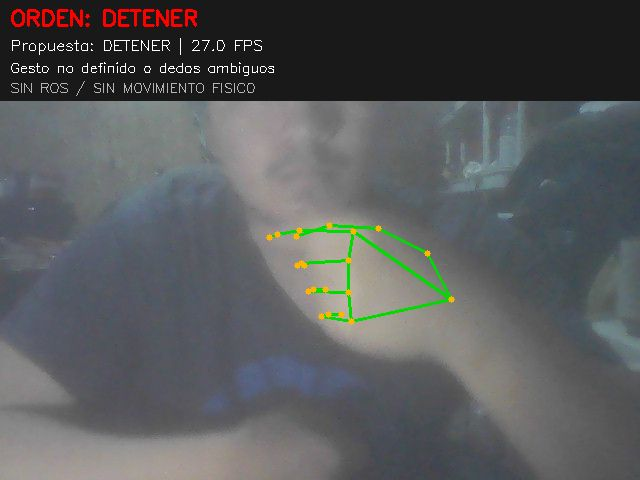

Prueba interrumpida.


Exception ignored in: <function HandLandmarker.__del__ at 0x000001FD0B64A7A0>
Traceback (most recent call last):
  File "d:\proyecto_vision\turtlebot4-vision-proyecto\.venv\Lib\site-packages\mediapipe\tasks\python\vision\hand_landmarker.py", line 612, in __del__
    self.close()
  File "d:\proyecto_vision\turtlebot4-vision-proyecto\.venv\Lib\site-packages\mediapipe\tasks\python\vision\hand_landmarker.py", line 588, in close
    self._lib.MpHandLandmarkerClose(self._handle)  # pyrefly: ignore[missing-attribute]
  File "d:\proyecto_vision\turtlebot4-vision-proyecto\.venv\Lib\site-packages\mediapipe\tasks\python\core\serial_dispatcher.py", line 74, in shutdown_aware_handler
    return handler(*args, **kwargs)
  File "d:\proyecto_vision\turtlebot4-vision-proyecto\.venv\Lib\site-packages\mediapipe\tasks\python\core\mediapipe_c_utils.py", line 142, in dispatcher_wrapper
    executor.submit(dispatch_and_free).result()
  File "C:\Users\lvera\AppData\Local\Programs\Python\Python313\Lib\concurre

Camara liberada. Orden final: DETENER.


In [8]:
ejecutar_webcam()

**6. Registrar qué ocurre.** Prueba primero palma y ausencia de mano; luego cada dirección por al menos un segundo. Repite con ambas manos, diferentes distancias y otra persona. Observa si la propuesta es correcta y cuánto tarda la orden estable. Revisa también dos manos, diagonales y movimientos breves: deberían detener.

Anota intentos, aciertos, errores y FPS. Las 12 pruebas de `tests/test_gestos.py` cubren geometría y tiempos con datos sintéticos, no precisión con personas. Puedes ejecutarlas en una terminal desde la raíz de Proyecto2:

```bash
.venv/bin/python -m unittest discover -s "task 2/tests" -t "task 2" -v
```

Antes de compartir el notebook, borra las salidas de cámara. Esta prueba local funciona sin Gazebo. La integración con el simulador se encuentra en `INTEGRACION_GESTOS.md` y reutiliza las mismas reglas y el filtro de este notebook.

La [guía del profesor](https://github.com/Tilinpro19/turtlebot67) ayudará con cámara ROS, conexión y teleoperación. No hace falta clonarla para ejecutar este notebook.